# 06 — Correções a partir do diagnóstico do especialista

O notebook 04 mostrou onde o sistema erra, pelas 25 respostas que um advogado revisor avaliou às cegas. O maior gargalo é a geração. Os erros mais comuns são:
- citação errada;
- regra distorcida;
- norma citada sem estar nas fontes;
- abertura contraditória.

Este notebook registra as correções aplicadas e mede o efeito delas.

| Correção | Onde | Situação |
|---|---|---|
| **Prompt v3:** regras de citação e de precisão acrescentadas ao prompt do grupo, mais a data atual e o tipo de cada fonte | `src/integracao/prompt_juridico.py` (`REGRAS_V3`, `build_rag_prompt(..., versao='v3')`) | implementado |
| **Validador v3:** confere, depois da geração, as falhas detectáveis por regra | `src/integracao/guardrails.py` (`verificar_saida(..., versao='v3')`) | implementado e medido nas respostas atuais |
| Nova geração com o prompt v3, mesmas fontes, e novo julgamento | Kaggle: gerador Qwen3 8B, juiz Gemma 3 27B | a executar |
| Critérios novos no juiz | `src/integracao/juiz.py` | a fazer |

**A versão original continua intacta.** O `SYSTEM_PROMPT_LEGAL` do grupo e o guardrail original (`versao='v1'`) não mudaram. O prompt v1 reproduz byte a byte os 111 pedidos já exportados, e os notebooks 03 a 05 continuam reproduzíveis. A versão v3 é escolhida no pedido (`versao_prompt='v3'`), e a revisão usa o validador correspondente.

## 1. Configuração e carga dos dados

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/integracao').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.integracao import guardrails as g
from src.integracao.prompt_juridico import REGRAS_V3

CORRECOES = ROOT / 'reports/integracao/correcoes'
antes = pd.read_csv(CORRECOES / 'validador_v3_respostas_v1.csv')
diag = pd.read_csv(ROOT / 'reports/integracao/juiz/diagnostico_especialista_27b.csv')
arquivo_depois = CORRECOES / 'validador_v3_respostas_v3.csv'
depois = pd.read_csv(arquivo_depois) if arquivo_depois.exists() else None
CODIGOS = ['norma_fora_das_fontes', 'sem_marcacao_fonte', 'lei_citada_com_decisao', 'abertura_categorica',
           'citacao_em_lote', 'metadado_interno']
ROTULOS = {'norma_fora_das_fontes': 'Norma fora das fontes', 'sem_marcacao_fonte': 'Sem [Fonte N]',
           'lei_citada_com_decisao': 'Lei sustentada só por decisão', 'abertura_categorica': 'Abertura sim/não condicionada',
           'citacao_em_lote': 'Mais de 2 fontes na frase', 'metadado_interno': 'Metadado interno exposto'}
print(f'Respostas atuais avaliadas: {len(antes)} · nova geração (v3): {"disponível" if depois is not None else "ainda não executada"}')

Respostas atuais avaliadas: 111 · nova geração (v3): ainda não executada


## 2. Prompt v3

As regras 16 a 23 foram acrescentadas depois das 15 regras originais. Cada uma corresponde a um tipo de falha do diagnóstico:

| Regra | Falha que ataca (notebook 04) |
|---|---|
| 16. Só citar `[Fonte N]` se o texto da fonte contém a informação; no máximo 2 fontes por afirmação | citação errada |
| 17. Só citar normas que aparecem nas fontes; não completar de memória | completa de memória |
| 18. Decisão judicial não sustenta texto de lei; caso concreto não vira regra geral | citação errada, caso generalizado |
| 19. Regra primeiro, exceção depois; preservar as condições ("desde que", "salvo", "integralmente") | abertura contraditória, regra distorcida |
| 20. Normas de categoria específica (doméstico, rural, professor) só para essa categoria | escopo |
| 21. Citar exatamente o dispositivo que contém a informação | citação errada (CF art. 51, art. 3º, III) |
| 22. Resposta jurídica sempre com pelo menos uma `[Fonte N]` | sem marcação de fonte |
| 23. Usar a data atual e não expor metadados internos (como `in_force`) | prazos e normas temporárias, metadado vazado |

No prompt do usuário, o v3 informa também a **data atual** e o **tipo de cada fonte** (legislação ou decisão judicial). Ele deixa de mostrar o status interno de vigência.

In [2]:
print(REGRAS_V3)


REGRAS ADICIONAIS DE CITAÇÃO E DE PRECISÃO:
16. Só coloque [Fonte N] numa afirmação se o texto da Fonte N contém essa informação.
    Uma fonte que apenas menciona a mesma palavra não sustenta a afirmação.
    Cite no máximo duas fontes por afirmação e não junte várias fontes numa frase só.
17. Só cite lei, artigo, súmula, orientação jurisprudencial ou tema que apareça no texto
    de alguma fonte. Não complete com normas de memória. Se a norma necessária não estiver
    nas fontes, diga que ela não foi encontrada nas evidências, sem citá-la como se estivesse.
18. Para afirmar o que diz uma lei, use a fonte de legislação que contém o dispositivo.
    Uma decisão judicial não sustenta o texto de uma lei nem de uma súmula; ela mostra como
    um caso foi julgado. Apresente-a como "em um caso julgado pelo [tribunal], ...".
    Não transforme dados do caso concreto (cláusula de convenção, percentual, categoria,
    empresa) em regra geral.
19. Regra primeiro, exceção depois. Quando a resp

## 3. Validador v3

O validador v3 roda depois da geração, sobre o texto da resposta e as fontes entregues. Ele soma alertas novos aos do guardrail original:

| Alerta | O que confere | Efeito |
|---|---|---|
| `norma_fora_das_fontes` | Lei, súmula, OJ ou tema citado pelo número, e artigo de código (CLT, CF, CPC, CC), que não aparece em nenhuma fonte entregue | **bloqueia** |
| `sem_marcacao_fonte` | Resposta com conteúdo jurídico e nenhuma marcação `[Fonte N]` | **bloqueia** |
| `lei_citada_com_decisao` | Frase que cita norma e só aponta para decisões judiciais | alerta |
| `abertura_categorica` | Abre com "sim" ou "não" e depois condiciona ("no entanto", "depende", "salvo") | alerta |
| `citacao_em_lote` | Mais de duas fontes numa frase | alerta |
| `metadado_interno` | Status de vigência, caminho ou nome de arquivo na resposta | alerta |

**Quando uma resposta é bloqueada,** o fluxo atual manda o mesmo pedido para a LLM B (Llama 3.1 8B). Se ela também falhar, entra a resposta segura. Como o Llama foi pior como gerador, a ação mais adequada para esses alertas pode ser **gerar de novo com o próprio Qwen**, informando o motivo do bloqueio. Essa decisão fica para depois da medição da seção 6.

**O que o validador não confere:** se o conteúdo de um artigo corresponde à afirmação (por exemplo, "art. 482 = justa causa"). Ele só confere se a norma está nas fontes. Essa checagem exige o texto de referência de cada dispositivo e fica para uma próxima etapa.

## 4. Linha de base: o validador v3 nas 111 respostas atuais

As respostas atuais foram geradas com o prompt v1. Aplicar o validador v3 a elas mostra quanto ele pegaria hoje, antes de qualquer mudança na geração.

Bloqueadas pelo guardrail original (v1): 1 de 111
Bloqueadas pelo validador v3:           34 de 111 (31%)


,respostas com o alerta
Metadado interno exposto,1
Mais de 2 fontes na frase,3
Norma fora das fontes,14
Sem [Fonte N],21
Abertura sim/não condicionada,28
Lei sustentada só por decisão,30


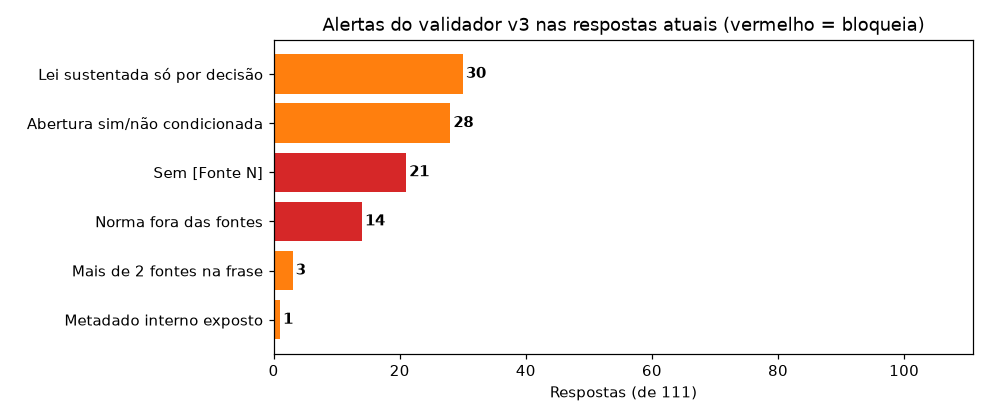

In [3]:
n = len(antes)
print(f'Bloqueadas pelo guardrail original (v1): {antes.bloqueada_v1.sum()} de {n}')
print(f'Bloqueadas pelo validador v3:           {antes.bloqueada_v3.sum()} de {n} ({antes.bloqueada_v3.mean():.0%})')
contagem = pd.Series({ROTULOS[c]: int((antes[c] > 0).sum()) for c in CODIGOS}).sort_values()
display(contagem.rename('respostas com o alerta').to_frame())

fig, ax = plt.subplots(figsize=(9, 3.8))
codigo_de = {r: k for k, r in ROTULOS.items()}
cores = ['#d62728' if codigo_de[r] in g.BLOQUEANTES_V3 else '#ff7f0e' for r in contagem.index]
ax.barh(contagem.index, contagem.values, color=cores)
for i, v in enumerate(contagem.values):
    ax.text(v + 0.5, i, str(v), va='center', fontweight='bold')
ax.set_xlim(0, n)
ax.set_xlabel(f'Respostas (de {n})')
ax.set_title('Alertas do validador v3 nas respostas atuais (vermelho = bloqueia)')
plt.tight_layout()
plt.savefig(CORRECOES / 'validador_v3_linha_de_base.png', dpi=150)
plt.show()

Normas citadas que não estão em nenhuma fonte entregue. A lista traz só o identificador da resposta e a norma, sem o texto. Todas foram conferidas no texto das respostas e são citações sem base, algumas erradas também no conteúdo. Por exemplo: prescrição de "1 ano" atribuída ao art. 1º, § 2º, da CLT; a Lei 11.350/2006, que trata de agentes comunitários de saúde, citada para prescrição; e o art. 114 "da CLT".

In [4]:
display(antes.dropna(subset=['normas_fora'])[['id', 'normas_fora']].reset_index(drop=True))

,id,normas_fora
0,q09_p1_JUS-009,lei 13486
1,q09_p1_JUS-018,art. 299 da CPC
2,q09_p1_JUS-031,art. 114 da CLT
3,q09_p1_JUS-034,lei 11350
4,q09_p1_JUS-045,art. 1 da CLT
5,q09_p1_JUS-046,art. 442 da CLT
6,q09_p2_FAQ22,lei 8212
7,q09_p2_FAQ28,lei 12527
8,q09_p2_FAQ30,art. 482 da CLT
9,q_dev_03,lei 11367


## 5. O validador pega o que o advogado apontou?

Cruzamento com a classificação das 25 observações do advogado revisor (notebook 04, seção 8). Para cada tipo de falha, a tabela mostra quantas dessas respostas recebem pelo menos um alerta do validador v3 e quantas ele bloquearia.

In [5]:
m = diag.merge(antes, on='id', suffixes=('', '_v3'))
m['algum_alerta'] = m[CODIGOS].gt(0).any(axis=1)
tipos = ['memoria', 'citacao', 'abertura', 'mecanismo', 'escopo', 'recall', 'ruido', 'precedente', 'fronteira']
linhas = []
for t in tipos:
    sub = m[m[t]]
    linhas.append({'tipo de falha (advogado)': t, 'respostas': len(sub), 'com alerta v3': int(sub.algum_alerta.sum()),
                   'bloqueadas v3': int(sub.bloqueada_v3.sum())})
display(pd.DataFrame(linhas))
print(f'Das 25 respostas reprovadas pelo advogado, o validador v3 bloquearia {m.bloqueada_v3.sum()} '
      f'e alertaria em {m.algum_alerta.sum()}.')
print(f'A regra fixa do juiz tinha aprovado 15; destas, o validador v3 bloquearia '
      f'{int(m[m.veredito_regra == "aprovada"].bloqueada_v3.sum())}.')

Das 25 respostas reprovadas pelo advogado, o validador v3 bloquearia 12 e alertaria em 20.
A regra fixa do juiz tinha aprovado 15; destas, o validador v3 bloquearia 8.


,tipo de falha (advogado),respostas,com alerta v3,bloqueadas v3
0,memoria,11,10,7
1,citacao,18,14,7
2,abertura,7,6,4
3,mecanismo,17,14,9
4,escopo,5,3,2
5,recall,13,10,6
6,ruido,14,11,8
7,precedente,8,7,3
8,fronteira,5,4,2


**Leitura.**

1. **O validador pega o que é verificável por regra.** Ele pega norma citada sem estar nas fontes, falta de `[Fonte N]`, lei sustentada só por decisão e abertura contraditória. Isso cobre boa parte das falhas de citação e de memória.
2. **As "leis de memória" estavam, na verdade, nos acórdãos entregues.** Ao conferir o texto das fontes, várias leis que o advogado classificou como "de memória" estavam nos acórdãos:
   - na pergunta do saque do FGTS: a Lei 13.979/2020 e o Decreto Legislativo 6/2020;
   - na do Imposto de Renda: a Lei 12.350/2010 e a IN 1.127/2011;
   - na de prescrição: a Lei 14.010/2020;
   - na do FGTS: a MP 946/2020.

   O advogado não tinha acesso ao texto dos trechos. Então nesses casos o erro não é inventar a norma: é tirar uma lei de uma decisão, muitas vezes uma regra temporária da pandemia, e apresentá-la como regra atual. Quem pega isso é o alerta `lei_citada_com_decisao`, junto com as regras 18 e 23 do prompt.
3. **Regra distorcida, recall, ruído, precedente e fronteira não são detectáveis por regra.** Distorcer a condição de uma súmula ou contar um prazo errado exige conhecimento jurídico: isso fica com o prompt v3 e com o juiz. Recall, ruído, precedente e fronteira são problemas da busca e do corpus: base de precedentes, recuperação em bloco e bases curadas.

## 6. Depois: nova geração com o prompt v3

**Procedimento:**
1. Gerar de novo as 111 respostas com o prompt v3, com as **mesmas fontes** dos pedidos atuais. Assim só o prompt muda.
2. Revisar as respostas com o validador v3: `python scripts/avaliar_validador_v3.py --respostas <respostas_v3.jsonl> --pedidos <pedidos_v3.jsonl> --rotulo v3`.
3. Julgar com o Gemma 3 27B e rodar este notebook de novo.

A célula abaixo compara o antes e o depois quando o arquivo da nova geração existir.

In [6]:
if depois is None:
    print('Nova geração com o prompt v3 ainda não executada.')
else:
    comp = pd.DataFrame({
        'prompt v1 (atual)': [int(antes.bloqueada_v3.sum())] + [int((antes[c] > 0).sum()) for c in CODIGOS],
        'prompt v3': [int(depois.bloqueada_v3.sum())] + [int((depois[c] > 0).sum()) for c in CODIGOS],
    }, index=['bloqueadas pelo validador v3'] + [ROTULOS[c] for c in CODIGOS])
    display(comp)
    ax = comp.plot.barh(figsize=(9, 4.2), color=['#7f7f7f', '#1f77b4'])
    ax.set_xlabel('Respostas')
    ax.set_title('Validador v3: respostas com prompt v1 × prompt v3')
    plt.tight_layout()
    plt.savefig(CORRECOES / 'validador_v3_antes_depois.png', dpi=150)
    plt.show()

Nova geração com o prompt v3 ainda não executada.


## 7. Conclusões até aqui

1. **As correções da geração estão implementadas sem quebrar o que existe.** O prompt v3 e o validador v3 são versões novas, escolhidas no pedido. O prompt original reproduz os 111 pedidos já exportados, e os testes de guardrails e geração passam.
2. **Hoje, o validador v3 bloquearia 34 das 111 respostas (31%),** contra 1 do guardrail original. Os motivos (uma resposta tem os dois):
   - 21 respostas sem nenhuma marcação de fonte. O notebook 04 contou 28 porque só aceitava `[Fonte N]` entre colchetes; o validador aceita também "(Fonte N)" e "Fonte N";
   - 14 com norma citada sem estar nas fontes (todas conferidas: são citações sem base, algumas também erradas no conteúdo).

   Nas 25 respostas que o advogado reprovou, o validador bloquearia 12 e alertaria em 20. Das 15 que a regra fixa do juiz tinha aprovado, ele bloquearia 8.
3. **Lei sustentada só por decisão é o alerta mais frequente (30 respostas).** A revisão das fontes mostrou que boa parte das "leis de memória" do diagnóstico vinha dos acórdãos entregues. A correção principal é a regra 18 do prompt.
4. **Falta medir o efeito do prompt v3,** com a nova geração no Kaggle (seção 6). Também falta decidir a ação quando o validador bloqueia: fallback para o Llama ou nova geração com o motivo do bloqueio.